In [ ]:

# Step 1: Connect Google Drive

from google.colab import drive
drive.mount('/content/drive')

# Step 2: Import required libraries

import pandas as pd
import numpy as np

# Step 3: Load the cleaned dataset

DATA_PATH = "/content/drive/MyDrive/shared iot/processed_data/cleaned_dataset.csv"

df = pd.read_csv(DATA_PATH)

# Step 4: Check whether the dataset loaded correctly

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumns:")
print(df.columns.tolist())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Dataset shape: (730242, 41)

First 5 rows:


,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Min,Max,AVG,Std,Tot size,IAT,Number,Variance,Attack_Type,Binary_Label
0,8.0,17,59.5,167.588483,0.0,0.0,0.0,0.0,0.0,0.0,...,163.0,1219.0,475.0,416.563721,475.0,0.005967,10.0,173525.333333,DNS_Spoofing,Attack
1,0.0,1,64.0,63205.304400,0.0,0.0,0.0,0.0,0.0,0.0,...,60.0,60.0,60.0,0.000000,60.0,0.000016,100.0,0.000000,DDoS-ICMP_Flood,Attack
2,20.0,6,64.0,15728.443394,1.0,0.0,1.0,0.0,0.0,0.0,...,60.0,60.0,60.0,0.000000,60.0,0.000065,100.0,0.000000,DDoS-RSTFINFLOOD,Attack
3,20.0,6,64.0,18109.338975,0.0,1.0,0.0,0.0,0.0,0.0,...,60.0,60.0,60.0,0.000000,60.0,0.000057,100.0,0.000000,DDoS-SYN_Flood,Attack
4,0.0,1,64.0,41490.790385,0.0,0.0,0.0,0.0,0.0,0.0,...,60.0,60.0,60.0,0.000000,60.0,0.000024,100.0,0.000000,DDoS-ICMP_Flood,Attack



Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Attack_Type', 'Binary_Label']


In [ ]:
# Step 2: Prepare binary classification labels

# Separate input features and target labels
X = df.drop(columns=["Attack_Type", "Binary_Label"])

y = df["Binary_Label"]

# Check the target labels
print("Target classes:")
print(y.value_counts())

print("\nNumber of classes:", y.nunique())

print("\nMissing values in target:", y.isnull().sum())


Target classes:
Binary_Label
Attack    706787
Benign     23455
Name: count, dtype: int64

Number of classes: 2

Missing values in target: 0


In [ ]:

# Step 3: Identify identical feature combinations

from sklearn.model_selection import GroupShuffleSplit

# Assign the same group ID to identical feature combinations
groups = pd.util.hash_pandas_object(X, index=False)

print("Total records:", len(X))
print("Unique feature groups:", groups.nunique())
print("Duplicate records:", len(X) - groups.nunique())


Total records: 730242
Unique feature groups: 693821
Duplicate records: 36421


In [ ]:

# Step 4: Remove groups with conflicting binary labels

group_label_counts = (
    pd.DataFrame({"group": groups, "label": y})
    .groupby("group")["label"]
    .nunique()
)

conflicting_groups = group_label_counts[
    group_label_counts > 1
].index

print("Groups with conflicting binary labels:", len(conflicting_groups))

# Keep only groups with consistent binary labels
valid_mask = ~groups.isin(conflicting_groups)

X = X.loc[valid_mask]
y = y.loc[valid_mask]
groups = groups.loc[valid_mask]

print("Records after removing conflicts:", len(X))


# Step 5: Perform stratified group splitting

from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]


# Step 6: Check the split

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))


Groups with conflicting binary labels: 25
Records after removing conflicts: 730180

Training set shape: (584236, 39)
Testing set shape: (145944, 39)

Training label distribution:
Binary_Label
Attack    565508
Benign     18728
Name: count, dtype: int64

Testing label distribution:
Binary_Label
Attack    141242
Benign      4702
Name: count, dtype: int64

Training class proportions:
Binary_Label
Attack    0.967944
Benign    0.032056
Name: proportion, dtype: float64

Testing class proportions:
Binary_Label
Attack    0.967782
Benign    0.032218
Name: proportion, dtype: float64


In [ ]:

# Step 5: Feature Scaling

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFeature scaling completed!")


Training data shape: (584236, 39)
Testing data shape: (145944, 39)

Feature scaling completed!


In [ ]:

# Step 6: Feature Selection using Random Forest

from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Train a Random Forest to identify important features
feature_selector = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

feature_selector.fit(X_train_scaled, y_train)

# Calculate feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": feature_selector.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking:")
display(feature_importance)

# Select the top 15 features
top_15_features = feature_importance["Feature"].head(15).tolist()

print("\nTop 15 selected features:")
print(top_15_features)


Feature Importance Ranking:


,Feature,Importance
37,Number,1.636824e-01
16,HTTPS,1.139196e-01
8,ack_flag_number,1.101935e-01
35,Tot size,7.535188e-02
36,IAT,7.352546e-02
3,Rate,6.821306e-02
0,Header_Length,6.648449e-02
33,AVG,6.243239e-02
11,ack_count,5.432357e-02
38,Variance,3.942782e-02



Top 15 selected features:
['Number', 'HTTPS', 'ack_flag_number', 'Tot size', 'IAT', 'Rate', 'Header_Length', 'AVG', 'ack_count', 'Variance', 'Max', 'Std', 'Tot sum', 'Time_To_Live', 'Min']


In [ ]:

# Get the column positions of the top 15 features
feature_indices = [
    X.columns.get_loc(feature)
    for feature in top_15_features
]

# Create datasets containing only the selected features
X_train_selected = X_train_scaled[:, feature_indices]
X_test_selected = X_test_scaled[:, feature_indices]

print("Original training data:", X_train_scaled.shape)
print("Original testing data:", X_test_scaled.shape)

print("\nSelected training data:", X_train_selected.shape)
print("Selected testing data:", X_test_selected.shape)


Original training data: (584236, 39)
Original testing data: (145944, 39)

Selected training data: (584236, 15)
Selected testing data: (145944, 15)



## majority class baseline


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

# Train on the original training data
baseline.fit(X_train, y_train)

# Predict on unseen test data
y_pred_baseline = baseline.predict(X_test)

# Evaluate
print("Baseline Accuracy:", accuracy_score(y_test, y_pred_baseline))
print("Baseline Macro-F1:", f1_score(y_test, y_pred_baseline, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))


Baseline Accuracy: 0.9677821630214328
Baseline Macro-F1: 0.4918136677971767

Classification Report:


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

      Attack       0.97      1.00      0.98    141242
      Benign       0.00      0.00      0.00      4702

    accuracy                           0.97    145944
   macro avg       0.48      0.50      0.49    145944
weighted avg       0.94      0.97      0.95    145944



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## logistic regression
using 39 features

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using all 39 features
lr_model.fit(X_train_scaled, y_train)

# Make predictions on the test data
y_pred_lr = lr_model.predict(X_test_scaled)

# Evaluate the model
print("Logistic Regression (39 Features)")
print("---------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Macro-F1:", f1_score(y_test, y_pred_lr, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Logistic Regression (39 Features)
---------------------------------
Accuracy: 0.9823014306857425
Macro-F1: 0.8539602747764852

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.74      0.70      0.72      4702

    accuracy                           0.98    145944
   macro avg       0.86      0.84      0.85    145944
weighted avg       0.98      0.98      0.98    145944



## logistic regression
using 15 features

In [ ]:

# Create Logistic Regression model
lr_model_15 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using only the selected 15 features
lr_model_15.fit(X_train_selected, y_train)

# Predict on the test data
y_pred_lr_15 = lr_model_15.predict(X_test_selected)

# Evaluate the model
print("Logistic Regression (15 Features)")
print("---------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr_15))
print("Macro-F1:", f1_score(y_test, y_pred_lr_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_15, zero_division=0))


Logistic Regression (15 Features)
---------------------------------
Accuracy: 0.9798895466754372
Macro-F1: 0.8363132428962163

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.69      0.67      0.68      4702

    accuracy                           0.98    145944
   macro avg       0.84      0.83      0.84    145944
weighted avg       0.98      0.98      0.98    145944



## decision tree
using 39 features

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight=None
)

# Train using all 39 features
dt_model.fit(X_train_scaled, y_train)

# Predict on test data
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate
print("Decision Tree (39 Features)")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Macro-F1:", f1_score(y_test, y_pred_dt, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))


Decision Tree (39 Features)
---------------------------
Accuracy: 0.9856931425752343
Macro-F1: 0.88433614984768

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.78      0.77      0.78      4702

    accuracy                           0.99    145944
   macro avg       0.89      0.88      0.88    145944
weighted avg       0.99      0.99      0.99    145944



## decision tree
using 15 features

In [ ]:

# Create Decision Tree model
dt_model_15 = DecisionTreeClassifier(
    random_state=42,
    class_weight=None
)

# Train using the selected 15 features
dt_model_15.fit(X_train_selected, y_train)

# Predict on test data
y_pred_dt_15 = dt_model_15.predict(X_test_selected)

# Evaluate
print("Decision Tree (15 Features)")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt_15))
print("Macro-F1:", f1_score(y_test, y_pred_dt_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_15, zero_division=0))


Decision Tree (15 Features)
---------------------------
Accuracy: 0.9848366496738475
Macro-F1: 0.8775768777181392

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.77      0.76      0.76      4702

    accuracy                           0.98    145944
   macro avg       0.88      0.87      0.88    145944
weighted avg       0.98      0.98      0.98    145944



## random forest
with 39 features


In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

# Train using all 39 features
rf_model.fit(X_train_scaled, y_train)

# Predict on test data
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluate
print("Random Forest (39 Features)")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Macro-F1:", f1_score(y_test, y_pred_rf, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Random Forest (39 Features)
---------------------------
Accuracy: 0.9895370827166584
Macro-F1: 0.9155963118248982

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.84      0.83      0.84      4702

    accuracy                           0.99    145944
   macro avg       0.92      0.91      0.92    145944
weighted avg       0.99      0.99      0.99    145944



## random forest
with 15 features

In [ ]:
rf_model_15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

rf_model_15.fit(X_train_selected, y_train)

y_pred_rf_15 = rf_model_15.predict(X_test_selected)

print("Random Forest (15 Features)")
print("---------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_15))
print("Macro-F1:", f1_score(y_test, y_pred_rf_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_15, zero_division=0))

Random Forest (15 Features)
---------------------------
Accuracy: 0.9889067039412377
Macro-F1: 0.9111908927135878

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.83      0.83      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.91      0.91      0.91    145944
weighted avg       0.99      0.99      0.99    145944



In [ ]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


## xgboost
using 39 features

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Convert class labels into numbers
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

# Train the model using all 39 features
xgb_model.fit(X_train_scaled, y_train_encoded)

# Make predictions
y_pred_xgb_encoded = xgb_model.predict(X_test_scaled)

# Convert predictions back to original labels
y_pred_xgb = label_encoder.inverse_transform(y_pred_xgb_encoded)

# Evaluate
print("XGBoost (39 Features)")
print("---------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Macro-F1:", f1_score(y_test, y_pred_xgb, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

XGBoost (39 Features)
---------------------
Accuracy: 0.9892287452721592
Macro-F1: 0.914670695062584

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.82      0.85      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.91      0.92      0.91    145944
weighted avg       0.99      0.99      0.99    145944



## xgboost
with 15 features

In [ ]:
# Create XGBoost model for 15 features
xgb_model_15 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

# Train using selected 15 features
xgb_model_15.fit(X_train_selected, y_train_encoded)

# Make predictions
y_pred_xgb_15_encoded = xgb_model_15.predict(X_test_selected)

# Convert predictions back to original labels
y_pred_xgb_15 = label_encoder.inverse_transform(y_pred_xgb_15_encoded)

# Evaluate
print("XGBoost (15 Features)")
print("---------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_15))
print("Macro-F1:", f1_score(y_test, y_pred_xgb_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_15, zero_division=0))

XGBoost (15 Features)
---------------------
Accuracy: 0.988776517020227
Macro-F1: 0.9116617558198166

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.81      0.85      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.90      0.92      0.91    145944
weighted avg       0.99      0.99      0.99    145944



In [ ]:
y_train_mlp = label_encoder.transform(y_train)
y_test_mlp = label_encoder.transform(y_test)

print("Training labels:", np.unique(y_train_mlp))
print("Testing labels:", np.unique(y_test_mlp))

Training labels: [0 1]
Testing labels: [0 1]


## mlp
using 39 features

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_model.fit(X_train_scaled, y_train_mlp)

y_pred_mlp_encoded = mlp_model.predict(X_test_scaled)
y_pred_mlp = label_encoder.inverse_transform(y_pred_mlp_encoded)

print("MLP (39 Features)")
print("-----------------")
print("Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("Macro-F1:", f1_score(y_test, y_pred_mlp, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_mlp, zero_division=0))

MLP (39 Features)
-----------------
Accuracy: 0.9877624294249849
Macro-F1: 0.902000052070935

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.81      0.81      0.81      4702

    accuracy                           0.99    145944
   macro avg       0.90      0.90      0.90    145944
weighted avg       0.99      0.99      0.99    145944



## mlp
using 15 features

In [ ]:
mlp_model_15 = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_model_15.fit(X_train_selected, y_train_mlp)

y_pred_mlp_15_encoded = mlp_model_15.predict(X_test_selected)
y_pred_mlp_15 = label_encoder.inverse_transform(y_pred_mlp_15_encoded)

print("MLP (15 Features)")
print("-----------------")
print("Accuracy:", accuracy_score(y_test, y_pred_mlp_15))
print("Macro-F1:", f1_score(y_test, y_pred_mlp_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_mlp_15, zero_division=0))

MLP (15 Features)
-----------------
Accuracy: 0.9868168612618539
Macro-F1: 0.8988250053960716

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.77      0.84      0.80      4702

    accuracy                           0.99    145944
   macro avg       0.88      0.92      0.90    145944
weighted avg       0.99      0.99      0.99    145944



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

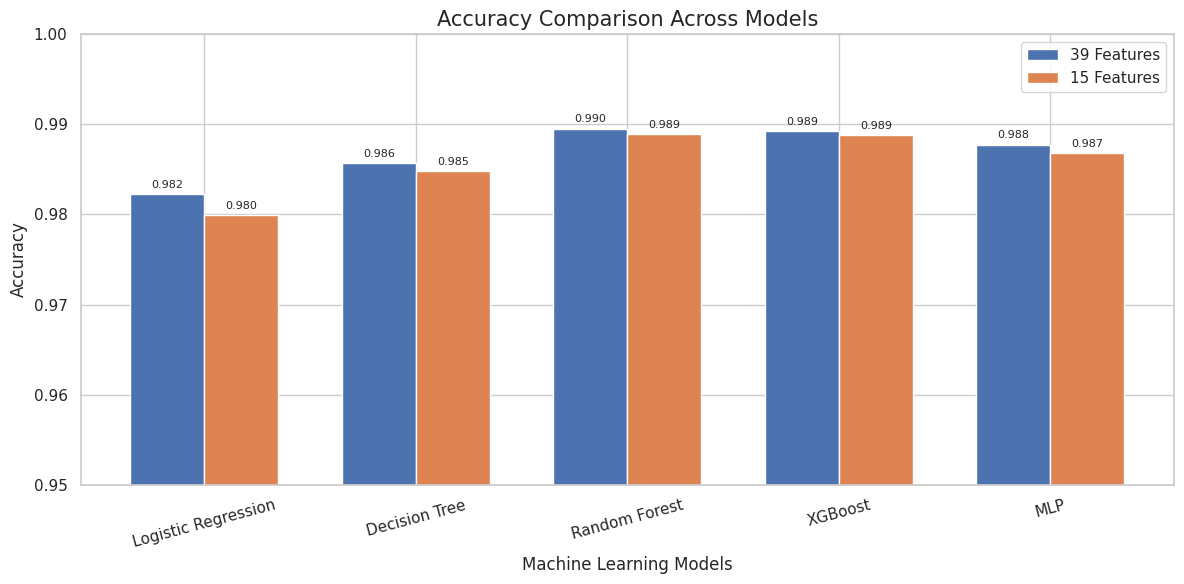

In [ ]:
models = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "MLP"]

accuracy_39 = [0.982301, 0.985693, 0.989537, 0.989229, 0.987762]
accuracy_15 = [0.979890, 0.984837, 0.988907, 0.988777, 0.986817]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width/2, accuracy_39, width, label="39 Features")
bars2 = ax.bar(x + width/2, accuracy_15, width, label="15 Features")

ax.set_title("Accuracy Comparison Across Models", fontsize=15)
ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim(0.95, 1.0)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

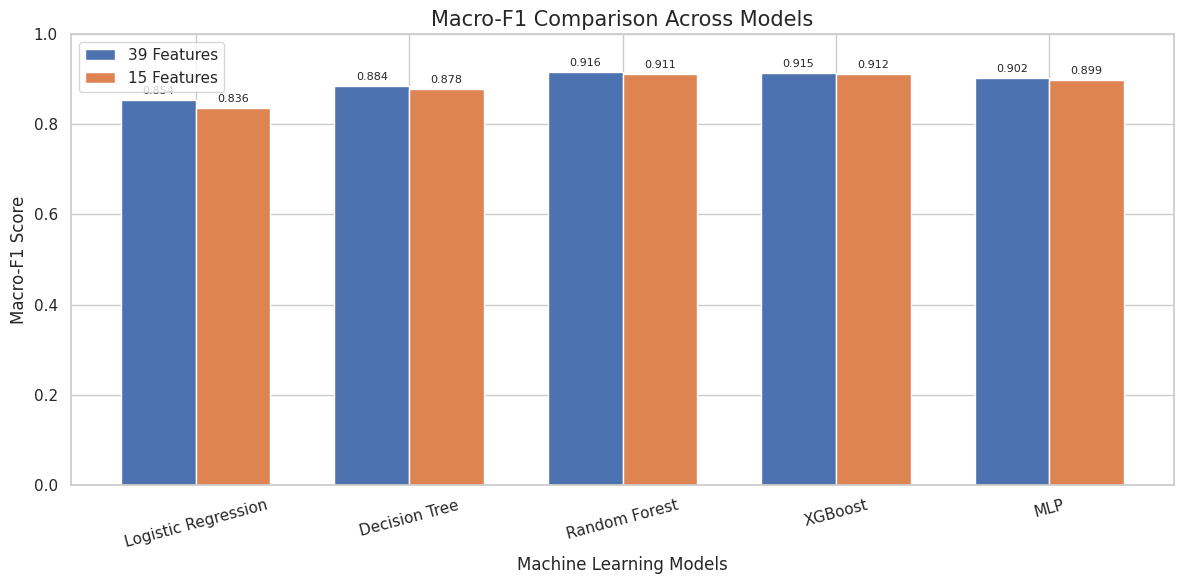

In [ ]:
macro_f1_39 = [0.853960, 0.884336, 0.915596, 0.914671, 0.902000]
macro_f1_15 = [0.836313, 0.877577, 0.911191, 0.911662, 0.898825]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width/2, macro_f1_39, width, label="39 Features")
bars2 = ax.bar(x + width/2, macro_f1_15, width, label="15 Features")

ax.set_title("Macro-F1 Comparison Across Models", fontsize=15)
ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Macro-F1 Score")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylim(0, 1)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig("macro_f1_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

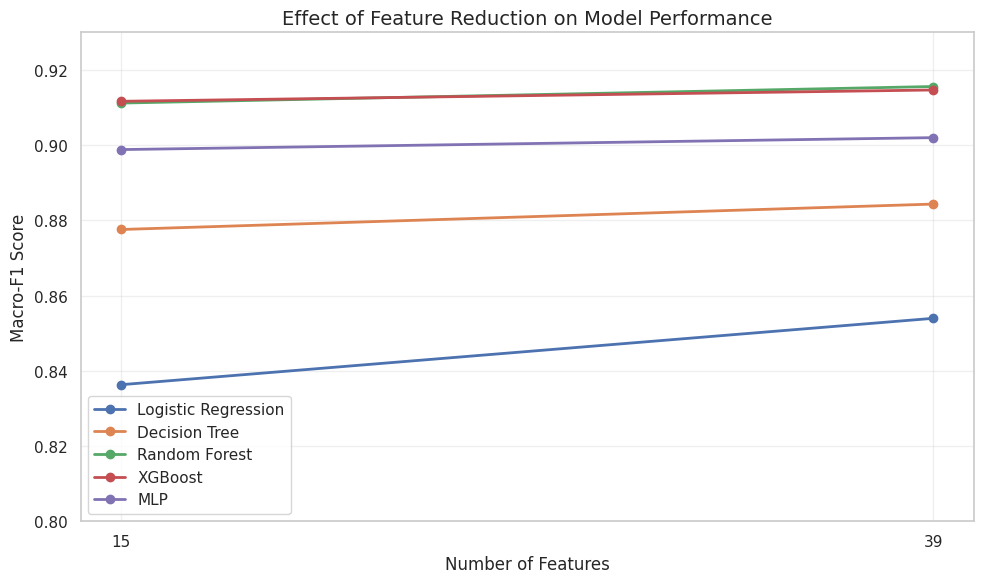

In [ ]:
feature_counts = [15, 39]

plt.figure(figsize=(10, 6))

plt.plot(feature_counts, [0.836313, 0.853960],
         marker="o", linewidth=2, label="Logistic Regression")

plt.plot(feature_counts, [0.877577, 0.884336],
         marker="o", linewidth=2, label="Decision Tree")

plt.plot(feature_counts, [0.911191, 0.915596],
         marker="o", linewidth=2, label="Random Forest")

plt.plot(feature_counts, [0.911662, 0.914671],
         marker="o", linewidth=2, label="XGBoost")

plt.plot(feature_counts, [0.898825, 0.902000],
         marker="o", linewidth=2, label="MLP")

plt.title("Effect of Feature Reduction on Model Performance", fontsize=14)
plt.xlabel("Number of Features")
plt.ylabel("Macro-F1 Score")

plt.xticks([15, 39])
plt.ylim(0.80, 0.93)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("feature_count_vs_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

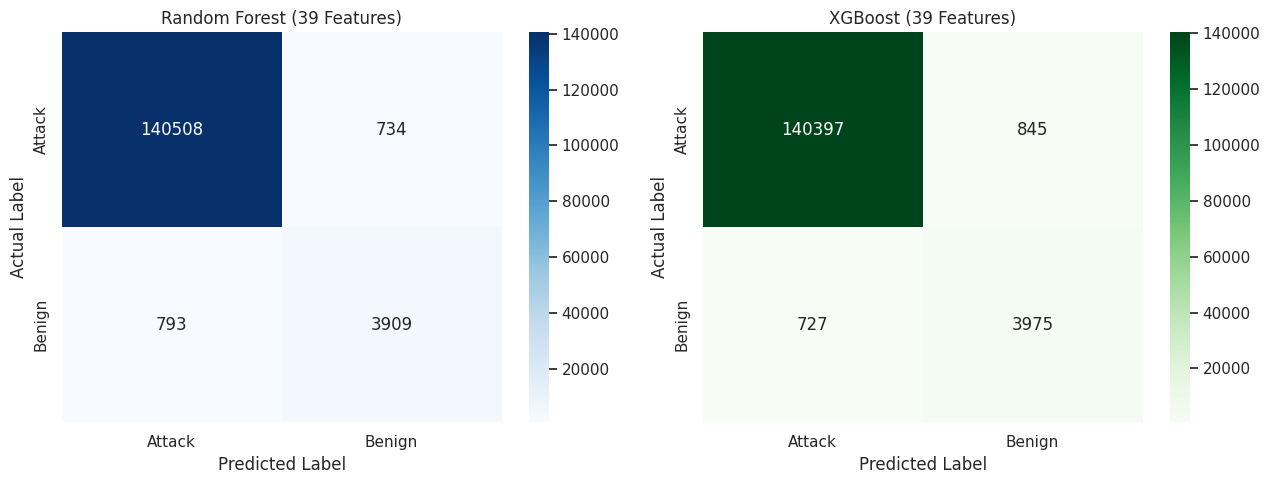

In [ ]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_labels = ["Attack", "Benign"]

# Random Forest
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_labels
)

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[0]
)

axes[0].set_title("Random Forest (39 Features)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# XGBoost
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=class_labels
)

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1]
)

axes[1].set_title("XGBoost (39 Features)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import os
import shutil

# Create figures folder
figures_folder = "/content/drive/MyDrive/shared iot/results/figures"
os.makedirs(figures_folder, exist_ok=True)

# Graphs generated earlier
graph_files = [
    "accuracy_comparison.png",
    "macro_f1_comparison.png",
    "feature_count_vs_macro_f1.png",
    "confusion_matrices.png"
]

# Copy graphs from Colab to Drive
for file in graph_files:
    if os.path.exists(file):
        shutil.copy(file, figures_folder)
        print(f"Saved: {file}")
    else:
        print(f"Not found: {file}")

print("\nGraph backup location:", figures_folder)

Saved: accuracy_comparison.png
Saved: macro_f1_comparison.png
Saved: feature_count_vs_macro_f1.png
Saved: confusion_matrices.png

Graph backup location: /content/drive/MyDrive/shared iot/results/figures


## random forest (with class weights to fix imbalancement)
 (using 39 features)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_weighted = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_weighted.fit(X_train_scaled, y_train)

y_pred_rf_weighted = rf_weighted.predict(X_test_scaled)

print("Random Forest with Class Weights (39 Features)")
print("------------------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_weighted))
print("Macro-F1:", f1_score(y_test, y_pred_rf_weighted, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_weighted, zero_division=0))

Random Forest with Class Weights (39 Features)
------------------------------------------------
Accuracy: 0.9893246724771145
Macro-F1: 0.9131909944212437

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.84      0.82      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.92      0.91      0.91    145944
weighted avg       0.99      0.99      0.99    145944



## random forest (with class weights to fix imbalancement)
using 15 features

In [ ]:
rf_weighted_15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_weighted_15.fit(X_train_selected, y_train)

y_pred_rf_weighted_15 = rf_weighted_15.predict(X_test_selected)

print("Random Forest with Class Weights (15 Features)")
print("------------------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_weighted_15))
print("Macro-F1:", f1_score(y_test, y_pred_rf_weighted_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_weighted_15, zero_division=0))

Random Forest with Class Weights (15 Features)
------------------------------------------------
Accuracy: 0.9888930000548155
Macro-F1: 0.91004680604644

Classification Report:
              precision    recall  f1-score   support

      Attack       0.99      0.99      0.99    141242
      Benign       0.83      0.82      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.91      0.91      0.91    145944
weighted avg       0.99      0.99      0.99    145944



In [ ]:
import gc

gc.collect()

print("Garbage collection completed.")

Garbage collection completed.


## xgboost with class weights to fix imbalancement
39 features

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Calculate minority-class weight using training data only
scale_weight = (
    (y_train_encoded == 0).sum() /
    (y_train_encoded == 1).sum()
)

print("Benign class weight:", scale_weight)

# Create model
xgb_weighted = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
    scale_pos_weight=scale_weight
)

# Train on 39 features
xgb_weighted.fit(X_train_scaled, y_train_encoded)

# Predict
y_pred_xgb_weighted_encoded = xgb_weighted.predict(X_test_scaled)

y_pred_xgb_weighted = label_encoder.inverse_transform(
    y_pred_xgb_weighted_encoded
)

# Evaluate
print("\nXGBoost with Class Weights (39 Features)")
print("-----------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_weighted))
print("Macro-F1:", f1_score(y_test, y_pred_xgb_weighted, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_weighted, zero_division=0))

Benign class weight: 30.195856471593338

XGBoost with Class Weights (39 Features)
-----------------------------------------
Accuracy: 0.9805404812804911
Macro-F1: 0.8785865771013411

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.98      0.99    141242
      Benign       0.62      1.00      0.77      4702

    accuracy                           0.98    145944
   macro avg       0.81      0.99      0.88    145944
weighted avg       0.99      0.98      0.98    145944



## xgboost with class weights to fix imbalancemnet
using 15 features

In [ ]:
xgb_weighted_15 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
    scale_pos_weight=scale_weight
)

# Train on 15 selected features
xgb_weighted_15.fit(X_train_selected, y_train_encoded)

# Predict
y_pred_xgb_weighted_15_encoded = xgb_weighted_15.predict(X_test_selected)

y_pred_xgb_weighted_15 = label_encoder.inverse_transform(
    y_pred_xgb_weighted_15_encoded
)

# Evaluate
print("XGBoost with Class Weights (15 Features)")
print("-----------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb_weighted_15))
print("Macro-F1:", f1_score(y_test, y_pred_xgb_weighted_15, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_weighted_15, zero_division=0))

XGBoost with Class Weights (15 Features)
-----------------------------------------
Accuracy: 0.9793893548210273
Macro-F1: 0.8731720110175234

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.98      0.99    141242
      Benign       0.61      1.00      0.76      4702

    accuracy                           0.98    145944
   macro avg       0.81      0.99      0.87    145944
weighted avg       0.99      0.98      0.98    145944



In [ ]:
import psutil

memory = psutil.virtual_memory()

print(f"RAM usage: {memory.percent}%")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

RAM usage: 76.9%
Available RAM: 2.93 GB


In [ ]:
print("39-feature training data:")
print(f"{X_train_scaled.nbytes / (1024**3):.2f} GB")

print("\n15-feature training data:")
print(f"{X_train_selected.nbytes / (1024**3):.2f} GB")

39-feature training data:
0.17 GB

15-feature training data:
0.07 GB


In [ ]:
import gc

gc.collect()

import psutil
memory = psutil.virtual_memory()

print(f"RAM usage: {memory.percent}%")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

RAM usage: 80.5%
Available RAM: 2.47 GB


## smote

In [ ]:
from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd
import gc

# Use float32 to reduce memory consumption
X_train_15_float = X_train_selected.astype(np.float32)

print("Before SMOTE:")
print(pd.Series(y_train_encoded).value_counts())

smote_15 = SMOTE(random_state=42)

X_train_smote_15, y_train_smote_15 = smote_15.fit_resample(
    X_train_15_float,
    y_train_encoded
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote_15).value_counts())

print("\nResampled data shape:", X_train_smote_15.shape)

Before SMOTE:
0    565508
1     18728
Name: count, dtype: int64

After SMOTE:
0    565508
1    565508
Name: count, dtype: int64

Resampled data shape: (1131016, 15)


In [ ]:
import gc

gc.collect()

import psutil
memory = psutil.virtual_memory()

print(f"RAM usage: {memory.percent}%")
print(f"Available RAM: {memory.available / (1024**3):.2f} GB")

RAM usage: 80.5%
Available RAM: 2.47 GB


## random forest with smote
15 features

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_smote_15 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_15.fit(X_train_smote_15, y_train_smote_15)

y_pred_rf_smote_15 = rf_smote_15.predict(X_test_selected)

print("Random Forest with SMOTE (15 Features)")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_rf_smote_15))
print("Macro-F1:", f1_score(y_test_encoded, y_pred_rf_smote_15, average="macro"))
print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_rf_smote_15,
    target_names=label_encoder.classes_,
    zero_division=0
))

Random Forest with SMOTE (15 Features)
Accuracy: 0.986097407224689
Macro-F1: 0.9033076042581094

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.99      0.99    141242
      Benign       0.72      0.94      0.81      4702

    accuracy                           0.99    145944
   macro avg       0.86      0.97      0.90    145944
weighted avg       0.99      0.99      0.99    145944



In [ ]:
import pandas as pd

smote_15_result = pd.DataFrame([{
    "Model": "Random Forest",
    "Features": 15,
    "Balancing": "SMOTE",
    "Accuracy": 0.986097407224689,
    "Macro-F1": 0.9033076042581094,
    "Benign Precision": 0.72,
    "Benign Recall": 0.94,
    "Benign F1": 0.81
}])

smote_15_result.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_15.csv",
    index=False
)

print("Result saved successfully!")

Result saved successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import numpy as np

DATA_PATH = "/content/drive/MyDrive/shared iot/processed_data/cleaned_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (730242, 41)
   Header_Length  Protocol Type  Time_To_Live          Rate  fin_flag_number  \
0            8.0             17          59.5    167.588483              0.0   
1            0.0              1          64.0  63205.304400              0.0   
2           20.0              6          64.0  15728.443394              1.0   
3           20.0              6          64.0  18109.338975              0.0   
4            0.0              1          64.0  41490.790385              0.0   

   syn_flag_number  rst_flag_number  psh_flag_number  ack_flag_number  \
0              0.0              0.0              0.0              0.0   
1              0.0              0.0              0.0              0.0   
2              0.0              1.0              0.0              0.0   
3              1.0              0.0              0.0              0.0   
4              0.0              0.0              0.0              0.0   

   ece_flag_number  ...    Min     Max    AVG       

In [5]:
print(df.shape)
print(df.columns.tolist())

(730242, 41)
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Attack_Type', 'Binary_Label']


In [6]:
X = df.drop(columns=["Attack_Type", "Binary_Label"])
y = df["Binary_Label"]

print("Features:", X.shape)
print("\nClass distribution:")
print(y.value_counts())

Features: (730242, 39)

Class distribution:
Binary_Label
Attack    706787
Benign     23455
Name: count, dtype: int64


In [7]:
groups = pd.util.hash_pandas_object(X, index=False)

group_label_counts = (
    pd.DataFrame({"group": groups, "label": y})
    .groupby("group")["label"]
    .nunique()
)

conflicting_groups = group_label_counts[
    group_label_counts > 1
].index

valid_mask = ~groups.isin(conflicting_groups)

X = X.loc[valid_mask]
y = y.loc[valid_mask]
groups = groups.loc[valid_mask]

print("Conflicting groups removed:", len(conflicting_groups))
print("Remaining records:", len(X))

Conflicting groups removed: 25
Remaining records: 730180


In [8]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training: (584236, 39)
Testing: (145944, 39)

Training labels:
Binary_Label
Attack    565508
Benign     18728
Name: count, dtype: int64

Testing labels:
Binary_Label
Attack    141242
Benign      4702
Name: count, dtype: int64


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

feature_selector = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

feature_selector.fit(X_train_scaled, y_train)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": feature_selector.feature_importances_
}).sort_values(by="Importance", ascending=False)

top_15_features = feature_importance["Feature"].head(15).tolist()

print("Top 15 features:")
print(top_15_features)

Top 15 features:
['Number', 'HTTPS', 'ack_flag_number', 'Tot size', 'IAT', 'Rate', 'Header_Length', 'AVG', 'ack_count', 'Variance', 'Max', 'Std', 'Tot sum', 'Time_To_Live', 'Min']


In [10]:
from sklearn.preprocessing import LabelEncoder

feature_indices = [
    X.columns.get_loc(feature)
    for feature in top_15_features
]

X_train_selected = X_train_scaled[:, feature_indices]
X_test_selected = X_test_scaled[:, feature_indices]

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Training (39 features):", X_train_scaled.shape)
print("Testing (39 features):", X_test_scaled.shape)

print("Training (15 features):", X_train_selected.shape)
print("Testing (15 features):", X_test_selected.shape)

print("\nEncoded classes:", label_encoder.classes_)

Training (39 features): (584236, 39)
Testing (39 features): (145944, 39)
Training (15 features): (584236, 15)
Testing (15 features): (145944, 15)

Encoded classes: ['Attack' 'Benign']


In [11]:
from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd

# Convert to float32 to reduce memory usage
X_train_39_float = X_train_scaled.astype(np.float32)

smote_39 = SMOTE(random_state=42)

print("Before SMOTE:")
print(pd.Series(y_train_encoded).value_counts())

X_train_smote_39, y_train_smote_39 = smote_39.fit_resample(
    X_train_39_float,
    y_train_encoded
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote_39).value_counts())

print("\nResampled dataset shape:", X_train_smote_39.shape)

Before SMOTE:
0    565508
1     18728
Name: count, dtype: int64

After SMOTE:
0    565508
1    565508
Name: count, dtype: int64

Resampled dataset shape: (1131016, 39)


## random forest with smote
39 features

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf_smote_39 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_smote_39.fit(X_train_smote_39, y_train_smote_39)

y_pred_rf_smote_39 = rf_smote_39.predict(X_test_scaled)

print("Random Forest with SMOTE (39 Features)")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_rf_smote_39))
print("Macro-F1:", f1_score(y_test_encoded, y_pred_rf_smote_39, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_rf_smote_39,
    target_names=label_encoder.classes_,
    zero_division=0
))

Random Forest with SMOTE (39 Features)
Accuracy: 0.9880707668694841
Macro-F1: 0.9113235482895438

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.99      0.99    141242
      Benign       0.77      0.90      0.83      4702

    accuracy                           0.99    145944
   macro avg       0.88      0.94      0.91    145944
weighted avg       0.99      0.99      0.99    145944



In [13]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# Extract Benign metrics
benign_precision, benign_recall, benign_f1, _ = (
    precision_recall_fscore_support(
        y_test_encoded,
        y_pred_rf_smote_39,
        labels=[label_encoder.transform(["Benign"])[0]],
        average=None,
        zero_division=0
    )
)

smote_39_result = pd.DataFrame([{
    "Model": "Random Forest",
    "Features": 39,
    "Balancing": "SMOTE",
    "Accuracy": accuracy_score(y_test_encoded, y_pred_rf_smote_39),
    "Macro-F1": f1_score(y_test_encoded, y_pred_rf_smote_39, average="macro"),
    "Benign Precision": benign_precision[0],
    "Benign Recall": benign_recall[0],
    "Benign F1": benign_f1[0]
}])

# Save to Google Drive
smote_39_result.to_csv(
    "/content/drive/MyDrive/shared iot/results/rf_smote_39.csv",
    index=False
)

print(smote_39_result)
print("\nResult saved to Google Drive!")

           Model  Features Balancing  Accuracy  Macro-F1  Benign Precision  \
0  Random Forest        39     SMOTE  0.988071  0.911324          0.770708   

   Benign Recall  Benign F1  
0       0.896427   0.828827  

Result saved to Google Drive!


## xgboost with smote
using 39 features

In [14]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

xgb_smote_39 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_smote_39.fit(
    X_train_smote_39,
    y_train_smote_39
)

y_pred_xgb_smote_39 = xgb_smote_39.predict(X_test_scaled)

print("XGBoost with SMOTE (39 Features)")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_xgb_smote_39))
print("Macro-F1:", f1_score(y_test_encoded, y_pred_xgb_smote_39, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_xgb_smote_39,
    target_names=label_encoder.classes_,
    zero_division=0
))

XGBoost with SMOTE (39 Features)
Accuracy: 0.984583127775037
Macro-F1: 0.8959024518853723

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.99      0.99    141242
      Benign       0.69      0.96      0.80      4702

    accuracy                           0.98    145944
   macro avg       0.84      0.97      0.90    145944
weighted avg       0.99      0.98      0.99    145944



In [16]:
from imblearn.over_sampling import SMOTE
import numpy as np

X_train_15_float = X_train_selected.astype(np.float32)

smote_15 = SMOTE(random_state=42)

X_train_smote_15, y_train_smote_15 = smote_15.fit_resample(
    X_train_15_float,
    y_train_encoded
)

print("Resampled shape:", X_train_smote_15.shape)
print(pd.Series(y_train_smote_15).value_counts())

Resampled shape: (1131016, 15)
0    565508
1    565508
Name: count, dtype: int64


## xgboost with smote
using 15 features

In [17]:
xgb_smote_15 = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_smote_15.fit(
    X_train_smote_15,
    y_train_smote_15
)

y_pred_xgb_smote_15 = xgb_smote_15.predict(X_test_selected)

print("XGBoost with SMOTE (15 Features)")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_xgb_smote_15))
print("Macro-F1:", f1_score(y_test_encoded, y_pred_xgb_smote_15, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_xgb_smote_15,
    target_names=label_encoder.classes_,
    zero_division=0
))

XGBoost with SMOTE (15 Features)
Accuracy: 0.9808625226114126
Macro-F1: 0.8792804622534611

Classification Report:
              precision    recall  f1-score   support

      Attack       1.00      0.98      0.99    141242
      Benign       0.63      0.99      0.77      4702

    accuracy                           0.98    145944
   macro avg       0.81      0.98      0.88    145944
weighted avg       0.99      0.98      0.98    145944



In [19]:
import os
import pandas as pd

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"

print("Files currently saved in Drive:\n")

for file in os.listdir(RESULTS_PATH):
    print(file)
    if file.endswith(".csv"):
        file_path = os.path.join(RESULTS_PATH, file)
        print(pd.read_csv(file_path))
        print("-" * 60)

Files currently saved in Drive:

figures
rf_smote_15.csv
           Model  Features Balancing  Accuracy  Macro-F1  Benign Precision  \
0  Random Forest        15     SMOTE  0.986097  0.903308              0.72   

   Benign Recall  Benign F1  
0           0.94       0.81  
------------------------------------------------------------
rf_smote_39.csv
           Model  Features Balancing  Accuracy  Macro-F1  Benign Precision  \
0  Random Forest        39     SMOTE  0.988071  0.911324          0.770708   

   Benign Recall  Benign F1  
0       0.896427   0.828827  
------------------------------------------------------------


In [20]:
import pandas as pd
import os

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"

xgb_smote_results = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Features": 39,
        "Balancing": "SMOTE",
        "Accuracy": 0.984583127775037,
        "Macro-F1": 0.8959024518853723,
        "Benign Precision": 0.69,
        "Benign Recall": 0.96,
        "Benign F1": 0.80
    },
    {
        "Model": "XGBoost",
        "Features": 15,
        "Balancing": "SMOTE",
        "Accuracy": 0.9808625226114126,
        "Macro-F1": 0.8792804622534611,
        "Benign Precision": 0.63,
        "Benign Recall": 0.99,
        "Benign F1": 0.77
    }
])

xgb_smote_results.to_csv(
    os.path.join(RESULTS_PATH, "xgb_smote_results.csv"),
    index=False
)

display(xgb_smote_results)

print("XGBoost SMOTE results saved!")

,Model,Features,Balancing,Accuracy,Macro-F1,Benign Precision,Benign Recall,Benign F1
0,XGBoost,39,SMOTE,0.984583,0.895902,0.69,0.96,0.80
1,XGBoost,15,SMOTE,0.980863,0.879280,0.63,0.99,0.77


XGBoost SMOTE results saved!


In [21]:
import pandas as pd
import os

RESULTS_PATH = "/content/drive/MyDrive/shared iot/results"
os.makedirs(RESULTS_PATH, exist_ok=True)

results = [
    # Original models
    ["Majority Baseline", 39, "None", 0.9677821630, 0.4918136678, 0.00, 0.00, 0.00],

    ["Logistic Regression", 39, "None", 0.9823014307, 0.8539602748, 0.74, 0.70, 0.72],
    ["Logistic Regression", 15, "None", 0.9798895467, 0.8363132429, 0.69, 0.67, 0.68],

    ["Decision Tree", 39, "None", 0.9856931426, 0.8843361498, 0.78, 0.77, 0.78],
    ["Decision Tree", 15, "None", 0.9848366497, 0.8775768777, 0.77, 0.76, 0.76],

    ["Random Forest", 39, "None", 0.9895370827, 0.9155963118, 0.84, 0.83, 0.84],
    ["Random Forest", 15, "None", 0.9889067039, 0.9111908927, 0.83, 0.83, 0.83],

    ["XGBoost", 39, "None", 0.9892287453, 0.9146706951, 0.82, 0.85, 0.83],
    ["XGBoost", 15, "None", 0.9887765170, 0.9116617558, 0.81, 0.85, 0.83],

    ["MLP", 39, "None", 0.9877624294, 0.9020000521, 0.81, 0.81, 0.81],
    ["MLP", 15, "None", 0.9868168613, 0.8988250054, 0.77, 0.84, 0.80],

    # Class-weighted models
    ["Random Forest", 39, "Class Weight", 0.9893246725, 0.9131909944, 0.84, 0.82, 0.83],
    ["Random Forest", 15, "Class Weight", 0.9888930001, 0.9100468060, 0.83, 0.82, 0.83],

    ["XGBoost", 39, "Class Weight", 0.9805404813, 0.8785865771, 0.62, 1.00, 0.77],
    ["XGBoost", 15, "Class Weight", 0.9793893548, 0.8731720110, 0.61, 1.00, 0.76],

    # SMOTE models
    ["Random Forest", 39, "SMOTE", 0.9880707669, 0.9113235483, 0.770708, 0.896427, 0.828827],
    ["Random Forest", 15, "SMOTE", 0.9860974072, 0.9033076043, 0.72, 0.94, 0.81],

    ["XGBoost", 39, "SMOTE", 0.9845831278, 0.8959024519, 0.69, 0.96, 0.80],
    ["XGBoost", 15, "SMOTE", 0.9808625226, 0.8792804623, 0.63, 0.99, 0.77]
]

columns = [
    "Model", "Features", "Balancing", "Accuracy",
    "Macro-F1", "Benign Precision", "Benign Recall", "Benign F1"
]

master_results = pd.DataFrame(results, columns=columns)

master_path = os.path.join(
    RESULTS_PATH,
    "binary_classification_results.csv"
)

master_results.to_csv(master_path, index=False)

print("Master results saved!")
print("Location:", master_path)
print("Total experiments:", len(master_results))

display(master_results)

Master results saved!
Location: /content/drive/MyDrive/shared iot/results/binary_classification_results.csv
Total experiments: 19


,Model,Features,Balancing,Accuracy,Macro-F1,Benign Precision,Benign Recall,Benign F1
0,Majority Baseline,39,None,0.967782,0.491814,0.000000,0.000000,0.000000
1,Logistic Regression,39,None,0.982301,0.853960,0.740000,0.700000,0.720000
2,Logistic Regression,15,None,0.979890,0.836313,0.690000,0.670000,0.680000
3,Decision Tree,39,None,0.985693,0.884336,0.780000,0.770000,0.780000
4,Decision Tree,15,None,0.984837,0.877577,0.770000,0.760000,0.760000
5,Random Forest,39,None,0.989537,0.915596,0.840000,0.830000,0.840000
6,Random Forest,15,None,0.988907,0.911191,0.830000,0.830000,0.830000
7,XGBoost,39,None,0.989229,0.914671,0.820000,0.850000,0.830000
8,XGBoost,15,None,0.988777,0.911662,0.810000,0.850000,0.830000
9,MLP,39,None,0.987762,0.902000,0.810000,0.810000,0.810000


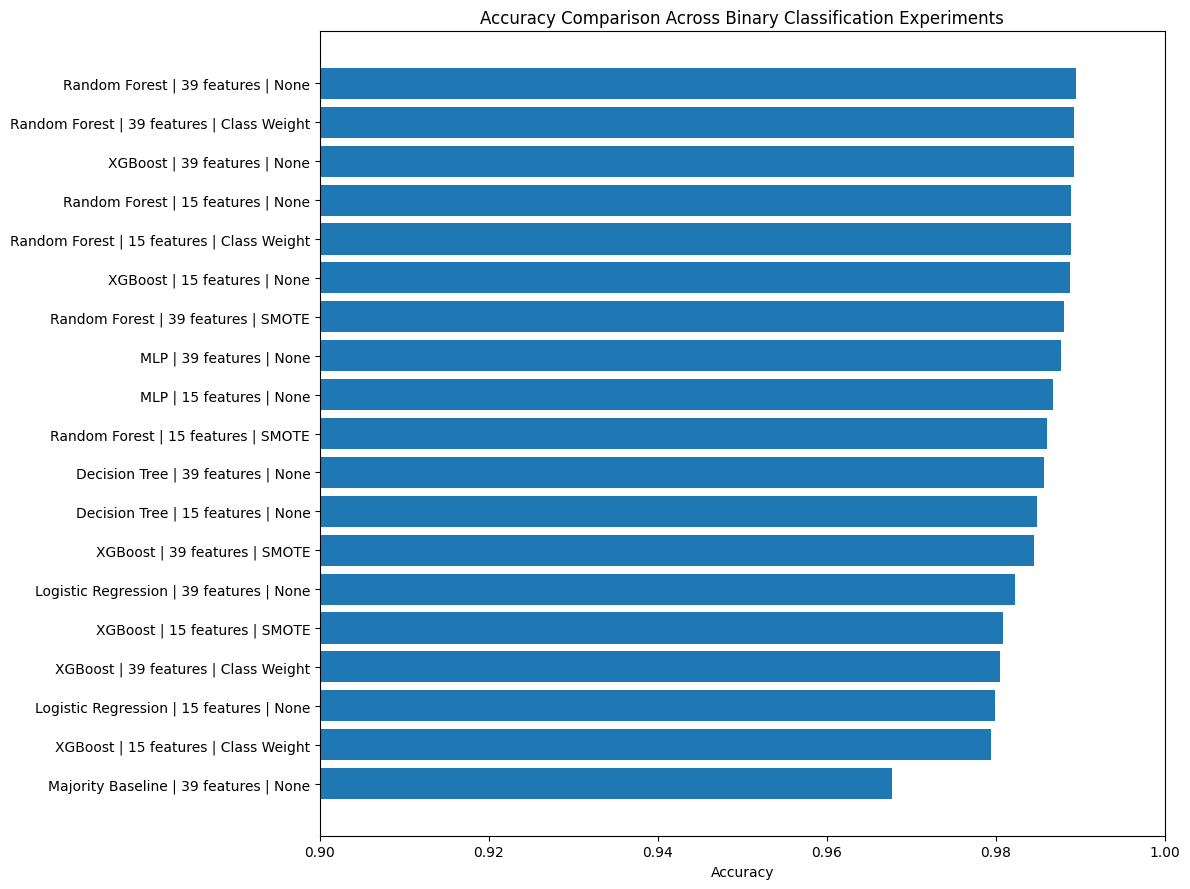

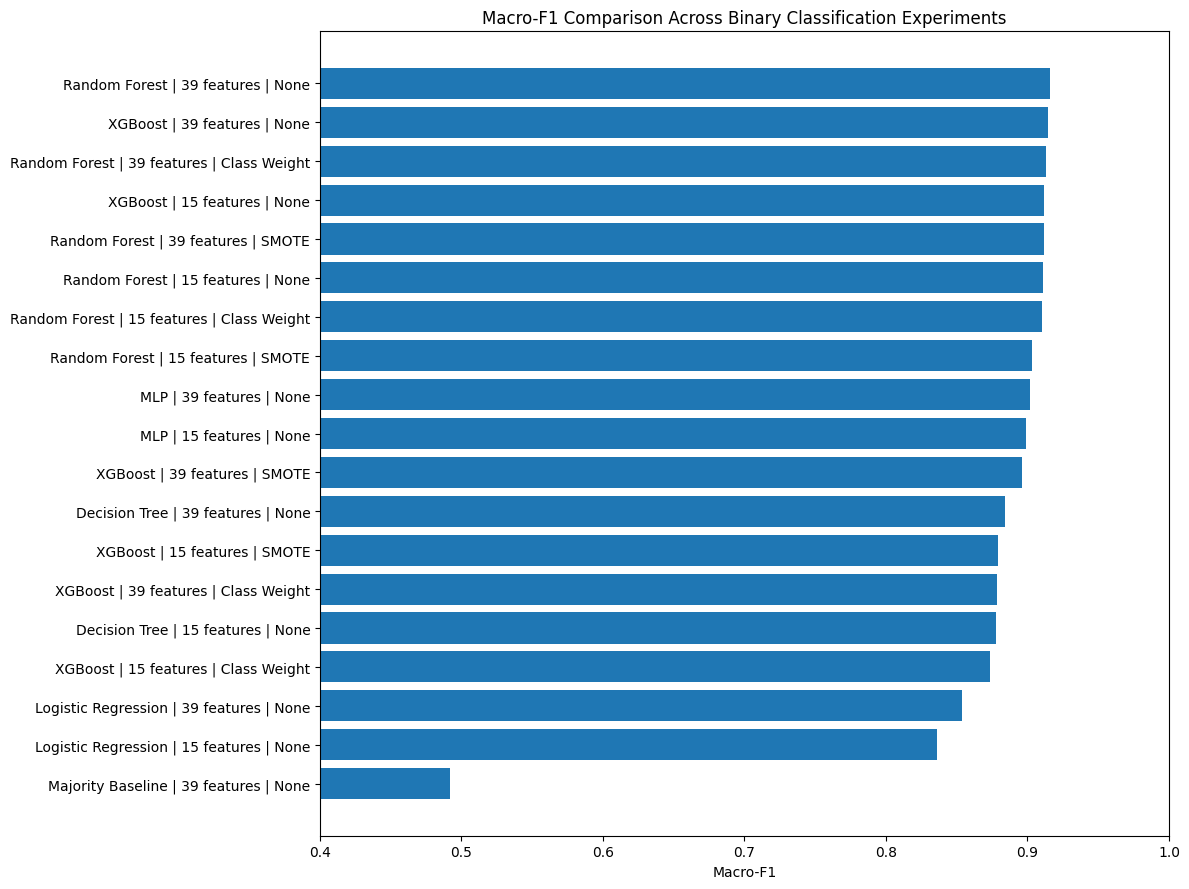

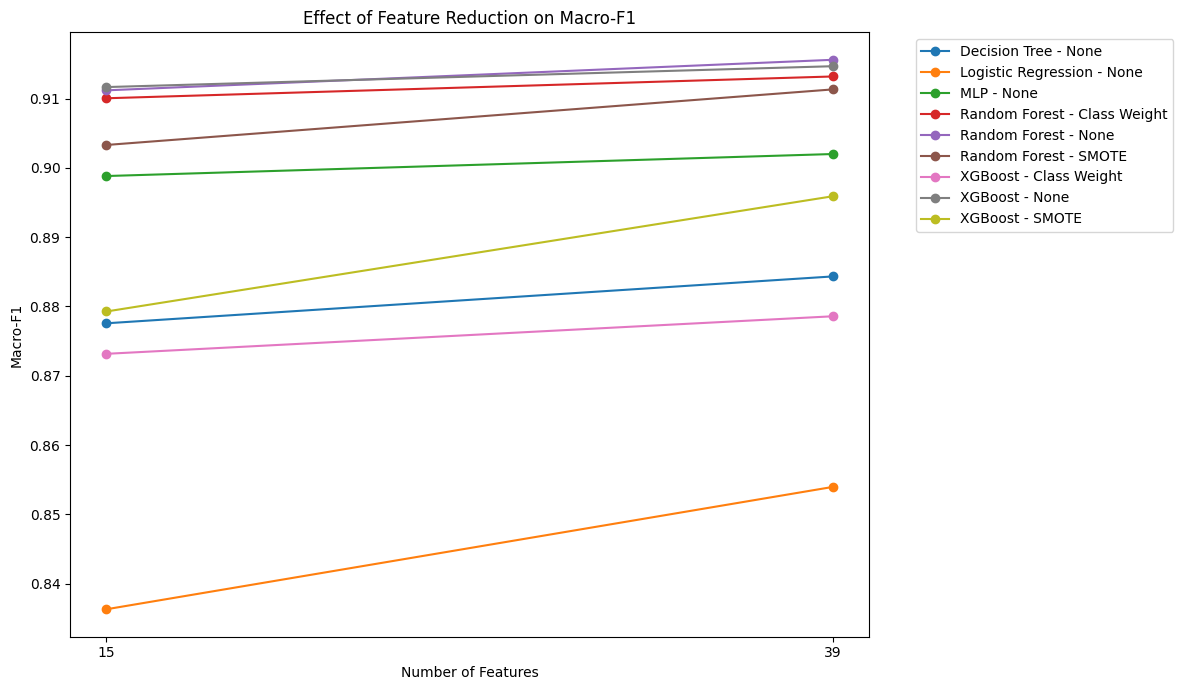

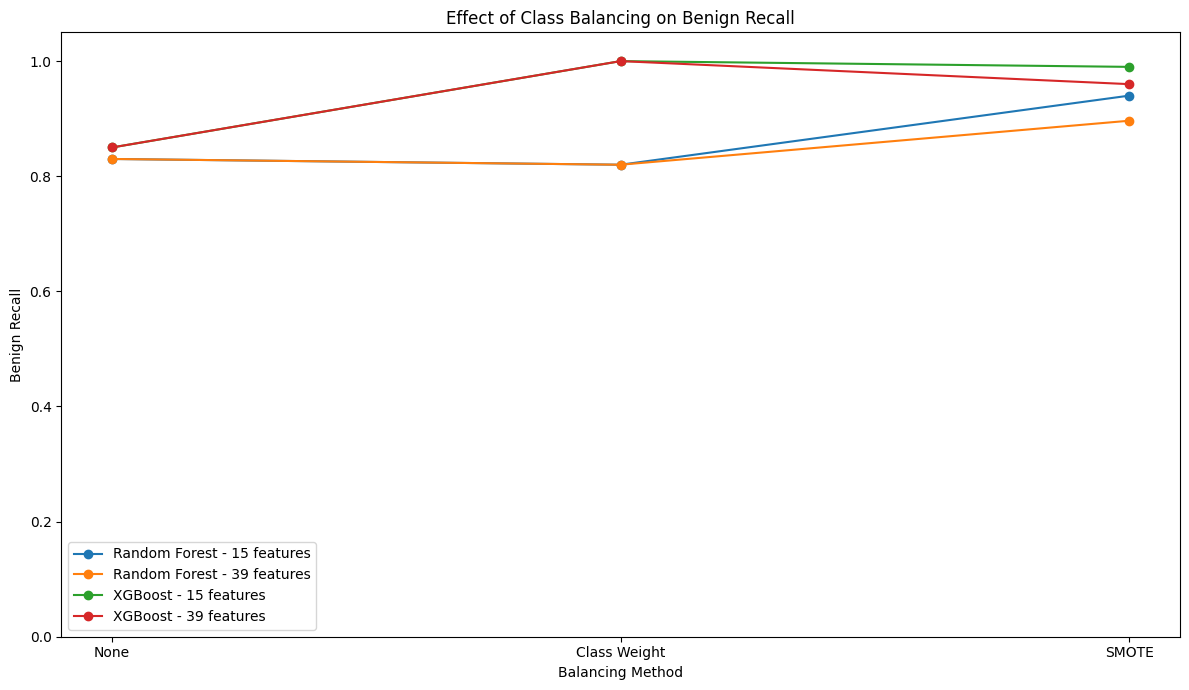


All four graphs saved in:
/content/drive/MyDrive/shared iot/results/figures


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import os

FIGURES_PATH = os.path.join(RESULTS_PATH, "figures")
os.makedirs(FIGURES_PATH, exist_ok=True)

# Create readable labels for each experiment
plot_df = master_results.copy()
plot_df["Experiment"] = (
    plot_df["Model"] + " | " +
    plot_df["Features"].astype(str) + " features | " +
    plot_df["Balancing"]
)

# GRAPH 1: Accuracy comparison
accuracy_df = plot_df.sort_values("Accuracy")

plt.figure(figsize=(12, 9))
plt.barh(accuracy_df["Experiment"], accuracy_df["Accuracy"])
plt.xlabel("Accuracy")
plt.title("Accuracy Comparison Across Binary Classification Experiments")
plt.xlim(0.90, 1.00)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "accuracy_comparison_final.png"), dpi=300)
plt.show()


# GRAPH 2: Macro-F1 comparison
f1_df = plot_df.sort_values("Macro-F1")

plt.figure(figsize=(12, 9))
plt.barh(f1_df["Experiment"], f1_df["Macro-F1"])
plt.xlabel("Macro-F1")
plt.title("Macro-F1 Comparison Across Binary Classification Experiments")
plt.xlim(0.40, 1.00)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "macro_f1_comparison_final.png"), dpi=300)
plt.show()


# GRAPH 3: Effect of reducing features from 39 to 15
feature_df = plot_df[plot_df["Balancing"].isin(["None", "Class Weight", "SMOTE"])]

plt.figure(figsize=(12, 7))

for (model, balancing), group in feature_df.groupby(["Model", "Balancing"]):
    group = group.sort_values("Features")
    if set(group["Features"]) == {15, 39}:
        plt.plot(
            group["Features"],
            group["Macro-F1"],
            marker="o",
            label=f"{model} - {balancing}"
        )

plt.xticks([15, 39])
plt.xlabel("Number of Features")
plt.ylabel("Macro-F1")
plt.title("Effect of Feature Reduction on Macro-F1")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "feature_reduction_final.png"), dpi=300)
plt.show()


# GRAPH 4: Benign recall across balancing methods
balance_df = plot_df[
    plot_df["Model"].isin(["Random Forest", "XGBoost"])
]

plt.figure(figsize=(12, 7))

for (model, features), group in balance_df.groupby(["Model", "Features"]):
    group = group.set_index("Balancing").reindex(
        ["None", "Class Weight", "SMOTE"]
    )

    plt.plot(
        group.index,
        group["Benign Recall"],
        marker="o",
        label=f"{model} - {features} features"
    )

plt.xlabel("Balancing Method")
plt.ylabel("Benign Recall")
plt.title("Effect of Class Balancing on Benign Recall")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "benign_recall_balancing_final.png"), dpi=300)
plt.show()

print("\nAll four graphs saved in:")
print(FIGURES_PATH)

Training: 39 Features - No Balancing
Confusion matrix:
[[140508    734]
 [   793   3909]]

Training: 15 Features - No Balancing
Confusion matrix:
[[140425    817]
 [   802   3900]]

Training: 39 Features - Class Weight
Confusion matrix:
[[140531    711]
 [   847   3855]]

Training: 15 Features - Class Weight
Confusion matrix:
[[140480    762]
 [   859   3843]]

Training: 39 Features - SMOTE
Confusion matrix:
[[139991   1251]
 [   495   4207]]

Training: 15 Features - SMOTE
Confusion matrix:
[[139494   1748]
 [   269   4433]]



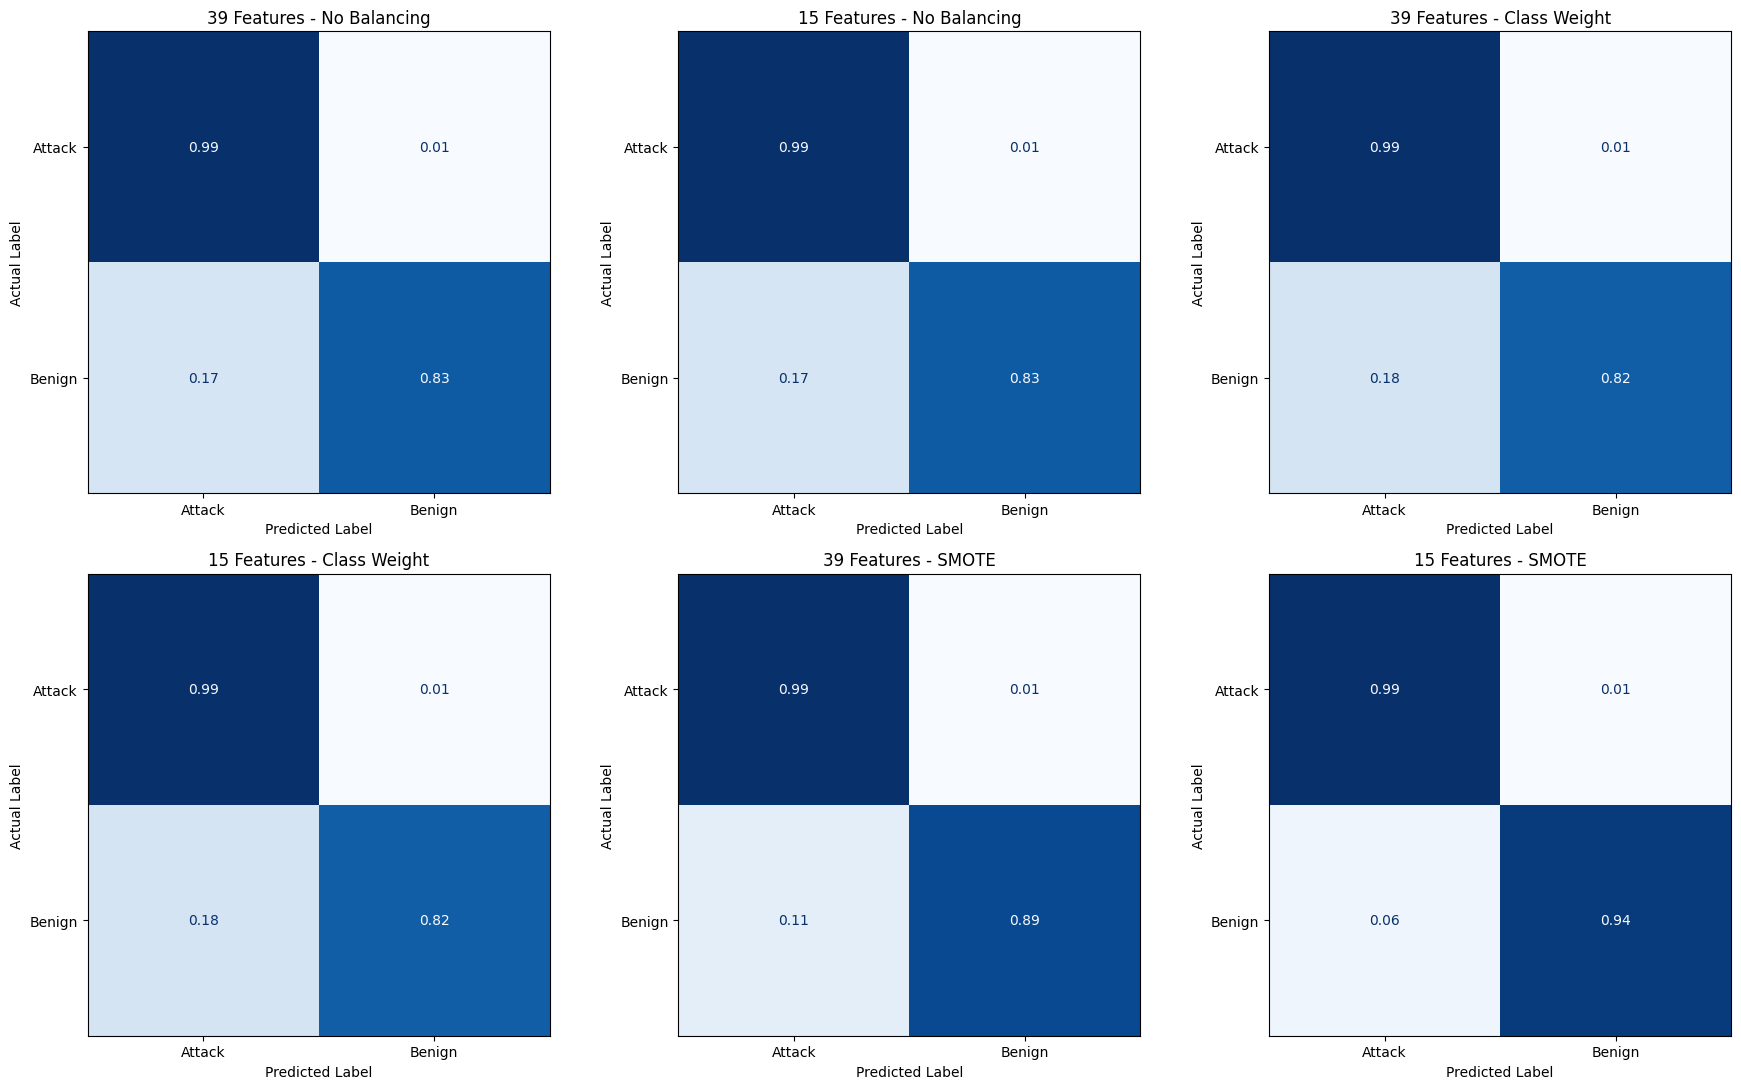

Saved confusion matrix figure: /content/drive/MyDrive/shared iot/results/figures/random_forest_confusion_matrices.png
Saved confusion matrix counts: /content/drive/MyDrive/shared iot/results/random_forest_confusion_matrix_counts.csv


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE

# Where to save the results
RESULTS_FOLDER = "/content/drive/MyDrive/shared iot/results"
FIGURES_FOLDER = os.path.join(RESULTS_FOLDER, "figures")

os.makedirs(FIGURES_FOLDER, exist_ok=True)

# Keep the class order consistent in every confusion matrix
labels = ["Attack", "Benign"]

# Store the results
confusion_results = []

# These are the six experiments:
# 39 features and 15 features, each with three balancing approaches.
experiments = [
    ("39 Features - No Balancing", X_train_scaled, X_test_scaled, None),
    ("15 Features - No Balancing", X_train_selected, X_test_selected, None),

    ("39 Features - Class Weight", X_train_scaled, X_test_scaled, "balanced"),
    ("15 Features - Class Weight", X_train_selected, X_test_selected, "balanced"),

    ("39 Features - SMOTE", X_train_scaled, X_test_scaled, "smote"),
    ("15 Features - SMOTE", X_train_selected, X_test_selected, "smote")
]

# Create a figure with six confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, (name, Xtr, Xte, balancing) in enumerate(experiments):

    print(f"Training: {name}")

    # Apply SMOTE only to training data
    if balancing == "smote":
        smote = SMOTE(random_state=42)
        Xtr_used, ytr_used = smote.fit_resample(Xtr, y_train)
        class_weight = None

    else:
        Xtr_used, ytr_used = Xtr, y_train
        class_weight = balancing

    # Train Random Forest
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight=class_weight
    )

    model.fit(Xtr_used, ytr_used)

    # Predict on the original, imbalanced test set
    predictions = model.predict(Xte)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=labels)

    # Save the raw counts
    confusion_results.append({
        "Experiment": name,
        "True Attack Predicted Attack": cm[0, 0],
        "True Attack Predicted Benign": cm[0, 1],
        "True Benign Predicted Attack": cm[1, 0],
        "True Benign Predicted Benign": cm[1, 1]
    })

    # Normalize each row so we can compare class-wise performance
    cm_normalized = confusion_matrix(
        y_test,
        predictions,
        labels=labels,
        normalize="true"
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm_normalized,
        display_labels=labels
    )

    display.plot(
        ax=axes[i],
        cmap="Blues",
        values_format=".2f",
        colorbar=False
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

    print("Confusion matrix:")
    print(cm)
    print()

plt.tight_layout()

# Save the figure
figure_path = os.path.join(
    FIGURES_FOLDER,
    "random_forest_confusion_matrices.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Save the raw confusion matrix counts
confusion_df = pd.DataFrame(confusion_results)

csv_path = os.path.join(
    RESULTS_FOLDER,
    "random_forest_confusion_matrix_counts.csv"
)

confusion_df.to_csv(csv_path, index=False)

print("Saved confusion matrix figure:", figure_path)
print("Saved confusion matrix counts:", csv_path)

display(confusion_df)

In [24]:
from IPython.display import display as show_table

show_table(confusion_df)

,Experiment,True Attack Predicted Attack,True Attack Predicted Benign,True Benign Predicted Attack,True Benign Predicted Benign
0,39 Features - No Balancing,140508,734,793,3909
1,15 Features - No Balancing,140425,817,802,3900
2,39 Features - Class Weight,140531,711,847,3855
3,15 Features - Class Weight,140480,762,859,3843
4,39 Features - SMOTE,139991,1251,495,4207
5,15 Features - SMOTE,139494,1748,269,4433
